In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
human_labels = pd.read_csv("../data/evaluation/human_labels.csv")
evaluation_queries = pd.read_csv("../data/evaluation/evaluation_queries.csv")

In [3]:
query_comparision = (
    human_labels.pivot_table(
        index = ["query_id", "rank"],
        columns ="method",
        values= "human_relevant"
    )
    .reset_index()    
)

query_comparision.head(15)

method,query_id,rank,CLIP,Color Histogram,ResNet
0,0,1,1.0,0.0,1.0
1,0,2,1.0,1.0,1.0
2,0,3,1.0,1.0,1.0
3,0,4,1.0,0.0,1.0
4,0,5,1.0,1.0,1.0
5,1,1,1.0,1.0,1.0
6,1,2,1.0,0.0,0.0
7,1,3,1.0,0.0,0.0
8,1,4,1.0,0.0,1.0
9,1,5,1.0,0.0,1.0


In [4]:
clip_wins = query_comparision[
    (query_comparision["CLIP"]==1)&
    (query_comparision["ResNet"]==0)
]
print("CLIP succeeds, ResNet fails:", len(clip_wins))

CLIP succeeds, ResNet fails: 34


In [5]:
clip_wins.head(10)

method,query_id,rank,CLIP,Color Histogram,ResNet
6,1,2,1.0,0.0,0.0
7,1,3,1.0,0.0,0.0
13,2,4,1.0,0.0,0.0
27,5,3,1.0,0.0,0.0
28,5,4,1.0,1.0,0.0
29,5,5,1.0,1.0,0.0
36,7,2,1.0,0.0,0.0
38,7,4,1.0,0.0,0.0
47,9,3,1.0,1.0,0.0
49,9,5,1.0,1.0,0.0


In [6]:
resnet_wins = query_comparision[
    (query_comparision["CLIP"]==0)&
    (query_comparision["ResNet"]==1)
]
print("ResNet succeeds, CLIP fails:", len(resnet_wins))

ResNet succeeds, CLIP fails: 10


In [7]:
resnet_wins.head(10)

method,query_id,rank,CLIP,Color Histogram,ResNet
26,5,2,0.0,0.0,1.0
37,7,3,0.0,0.0,1.0
39,7,5,0.0,0.0,1.0
77,15,3,0.0,0.0,1.0
101,20,2,0.0,1.0,1.0
113,22,4,0.0,1.0,1.0
140,28,1,0.0,1.0,1.0
141,28,2,0.0,0.0,1.0
142,28,3,0.0,0.0,1.0
143,28,4,0.0,0.0,1.0


In [8]:
def show_disagreement_examples(results, n=5):
    for _, row in results.head(n).iterrows():

        query_id = row["query_id"]
        rank = row["rank"]

        query = evaluation_queries[
            evaluation_queries["query_id"] == query_id
        ].iloc[0]

        candidates = human_labels[
            (human_labels["query_id"] == query_id) &
            (human_labels["rank"] == rank)
        ]

        print("=" * 60)
        print(f"Query {query_id} | Rank {rank}")
        print(
            f"Query room: {query['room']} | "
            f"Query style: {query['style']}"
        )

        # Query image
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(query["path"]))
        plt.title("Query")
        plt.axis("off")
        plt.show()

        # Candidate images from the two methods
        for method in ["CLIP", "ResNet"]:
            candidate = candidates[
                candidates["method"] == method
            ].iloc[0]

            print(
                f"{method}: "
                f"{candidate['candidate_room']} / "
                f"{candidate['candidate_style']} | "
                f"Human label: "
                f"{int(candidate['human_relevant'])}"
            )

            plt.figure(figsize=(4, 4))
            plt.imshow(
                Image.open(candidate["candidate_path"])
            )
            plt.title(
                f"{method} - Rank {rank}"
            )
            plt.axis("off")
            plt.show()

Query 1.0 | Rank 2.0
Query room: bedroom | Query style: modern


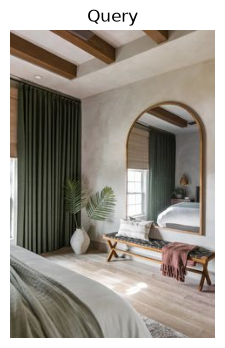

CLIP: living_room / minimalist | Human label: 1


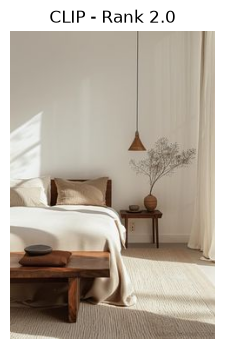

ResNet: kitchen / modern | Human label: 0


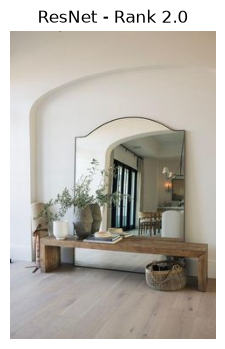

Query 1.0 | Rank 3.0
Query room: bedroom | Query style: modern


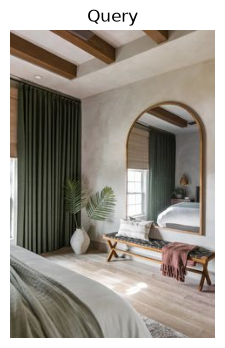

CLIP: bedroom / minimalist | Human label: 1


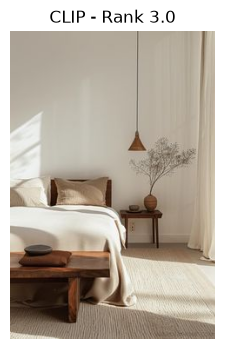

ResNet: living_room / scandinavian | Human label: 0


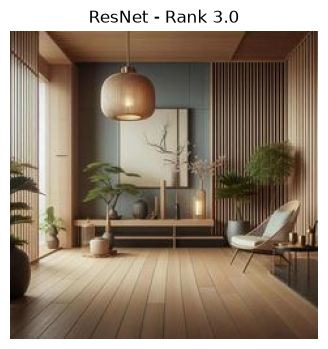

Query 2.0 | Rank 4.0
Query room: bedroom | Query style: minimalist


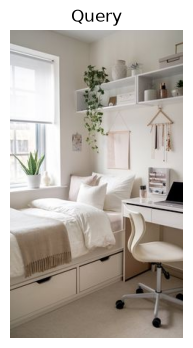

CLIP: bedroom / boho | Human label: 1


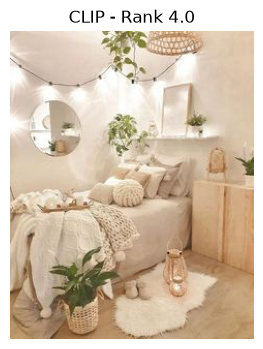

ResNet: living_room / scandinavian | Human label: 0


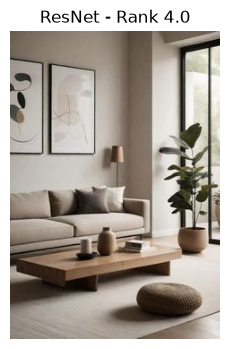

Query 5.0 | Rank 3.0
Query room: bedroom | Query style: industrial


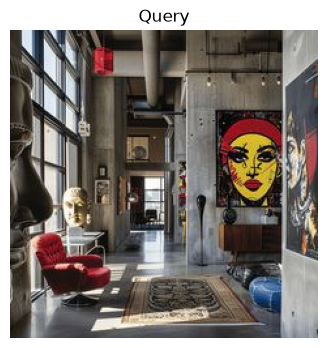

CLIP: living_room / industrial | Human label: 1


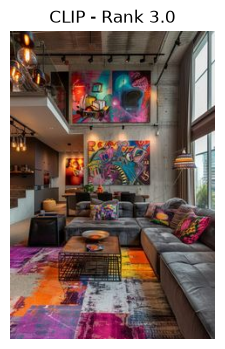

ResNet: bedroom / industrial | Human label: 0


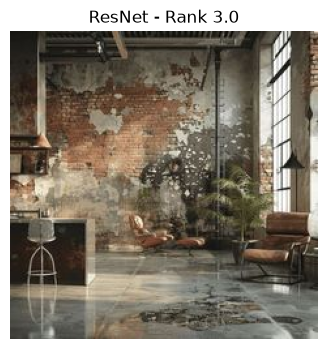

Query 5.0 | Rank 4.0
Query room: bedroom | Query style: industrial


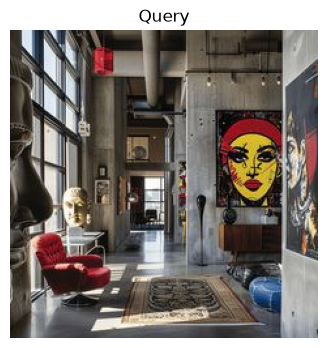

CLIP: bedroom / industrial | Human label: 1


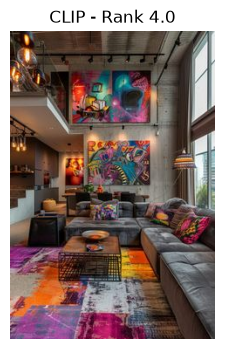

ResNet: living_room / industrial | Human label: 0


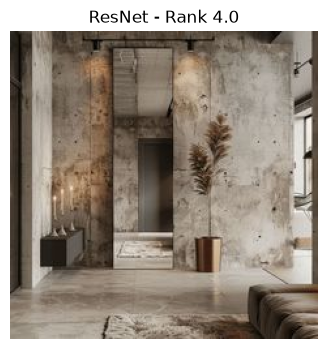

In [9]:
show_disagreement_examples(clip_wins, n=5)

In [10]:
query_rooms = evaluation_queries[
    ["query_id", "room", "style"]
].rename(
    columns={
        "room": "query_room",
        "style": "query_style"
    }
)

clip_wins_detail = clip_wins.merge(
    query_rooms,
    on="query_id",
    how="left"
)

resnet_wins_detail = resnet_wins.merge(
    query_rooms,
    on="query_id",
    how="left"
)

In [11]:
print("CLIP wins by query room:")
print(
    clip_wins_detail["query_room"]
    .value_counts()
)

print("\nResNet wins by query room:")
print(
    resnet_wins_detail["query_room"]
    .value_counts()
)

CLIP wins by query room:
query_room
bathroom       13
bedroom         9
kitchen         6
living_room     6
Name: count, dtype: int64

ResNet wins by query room:
query_room
bathroom    7
kitchen     2
bedroom     1
Name: count, dtype: int64


In [12]:
clip_wins_detail["candidate_room"] = (
    human_labels
    .set_index(
        ["query_id", "rank", "method"]
    )
    .loc[
        pd.MultiIndex.from_frame(
            clip_wins_detail[
                ["query_id", "rank"]
            ].assign(method="CLIP")
        )
    ]["candidate_room"]
    .values
)

In [13]:
print(
    "CLIP wins where candidate is a different room:",
    (
        clip_wins_detail["query_room"]
        != clip_wins_detail["candidate_room"]
    ).sum()
)

print(
    "CLIP wins where candidate is same room:",
    (
        clip_wins_detail["query_room"]
        == clip_wins_detail["candidate_room"]
    ).sum()
)

CLIP wins where candidate is a different room: 11
CLIP wins where candidate is same room: 23


Query 1.0 | Rank 2.0
Query room: bedroom | Query style: modern


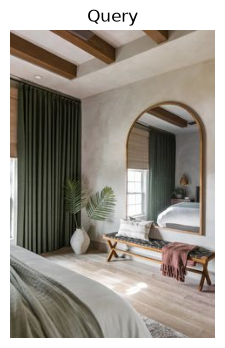

CLIP: living_room / minimalist | Human label: 1


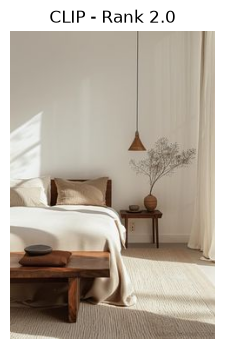

ResNet: kitchen / modern | Human label: 0


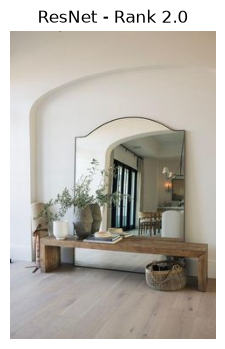

Query 1.0 | Rank 3.0
Query room: bedroom | Query style: modern


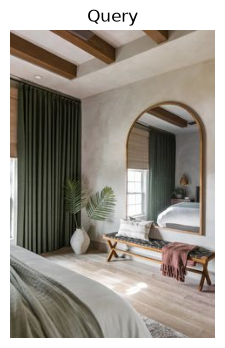

CLIP: bedroom / minimalist | Human label: 1


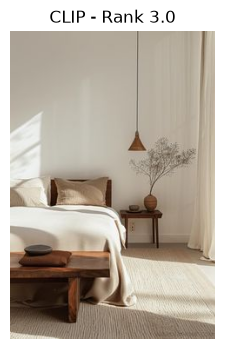

ResNet: living_room / scandinavian | Human label: 0


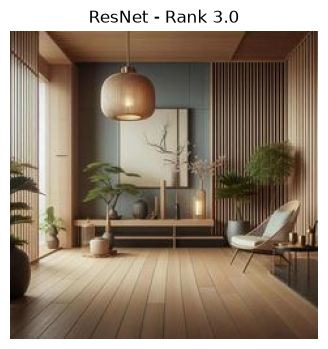

Query 2.0 | Rank 4.0
Query room: bedroom | Query style: minimalist


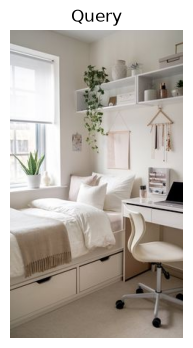

CLIP: bedroom / boho | Human label: 1


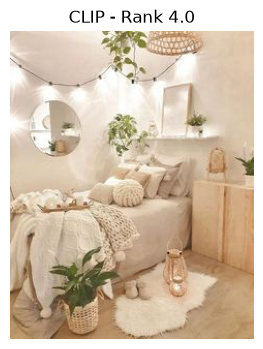

ResNet: living_room / scandinavian | Human label: 0


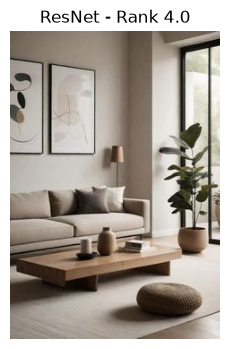

In [14]:
show_disagreement_examples(clip_wins, n=3)

Query 5.0 | Rank 2.0
Query room: bedroom | Query style: industrial


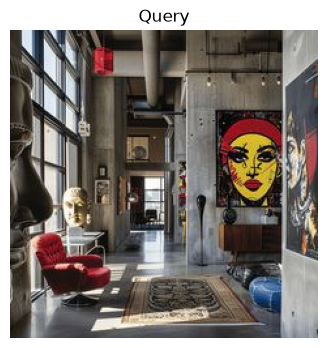

CLIP: living_room / industrial | Human label: 0


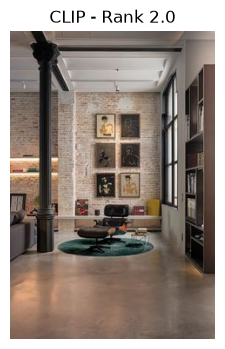

ResNet: living_room / industrial | Human label: 1


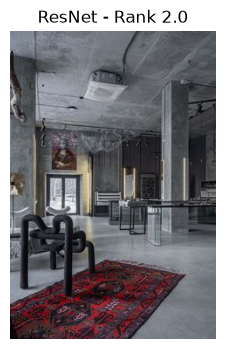

Query 7.0 | Rank 3.0
Query room: kitchen | Query style: modern


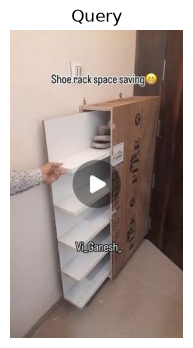

CLIP: kitchen / modern | Human label: 0


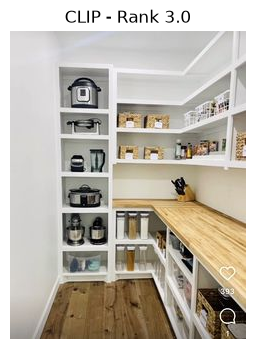

ResNet: kitchen / boho | Human label: 1


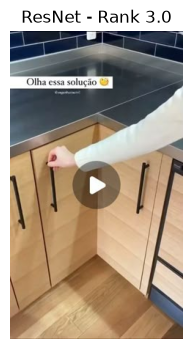

Query 7.0 | Rank 5.0
Query room: kitchen | Query style: modern


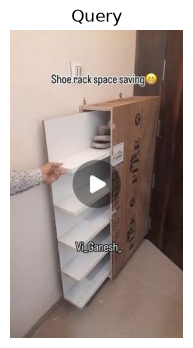

CLIP: kitchen / industrial | Human label: 0


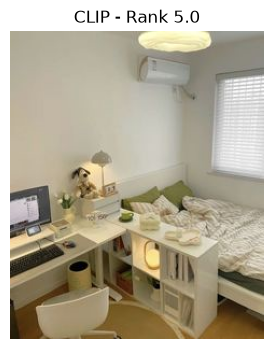

ResNet: bedroom / modern | Human label: 1


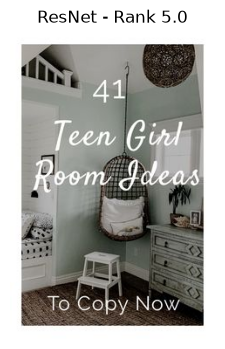

In [17]:
show_disagreement_examples(resnet_wins, n=3)

In [20]:
import pandas as pd

human_labels = pd.read_csv("../data/evaluation/human_labels.csv")

query_precision = (
    human_labels
    .groupby(["query_id", "method"])["human_relevant"]
    .mean()
    .reset_index(name="precision_at_5")
)

clip_resnet = query_precision.pivot(
    index="query_id",
    columns="method",
    values="precision_at_5"
)

clip_resnet.head()

method,CLIP,Color Histogram,ResNet
query_id,,,
0,1.0,0.6,1.0
1,1.0,0.2,0.6
2,1.0,0.0,0.8
3,1.0,0.2,1.0
4,1.0,1.0,1.0


In [21]:
from scipy.stats import wilcoxon

clip_vs_resnet = wilcoxon(
    clip_resnet["CLIP"],
    clip_resnet["ResNet"]
)

clip_vs_color = wilcoxon(
    clip_resnet["CLIP"],
    clip_resnet["Color Histogram"]
)

resnet_vs_color = wilcoxon(
    clip_resnet["ResNet"],
    clip_resnet["Color Histogram"]
)

print("CLIP vs ResNet")
print("Statistic:", clip_vs_resnet.statistic)
print("p-value:", clip_vs_resnet.pvalue)

print("\nCLIP vs Color Histogram")
print("Statistic:", clip_vs_color.statistic)
print("p-value:", clip_vs_color.pvalue)

print("\nResNet vs Color Histogram")
print("Statistic:", resnet_vs_color.statistic)
print("p-value:", resnet_vs_color.pvalue)

CLIP vs ResNet
Statistic: 20.5
p-value: 0.004365898396944582

CLIP vs Color Histogram
Statistic: 10.5
p-value: 3.921573560924458e-05

ResNet vs Color Histogram
Statistic: 62.5
p-value: 0.00693154567030103


In [23]:
p_values = [
    clip_vs_resnet.pvalue,
    clip_vs_color.pvalue,
    resnet_vs_color.pvalue
]

comparisons = [
    "CLIP vs ResNet",
    "CLIP vs Color Histogram",
    "ResNet vs Color Histogram"
]

order = sorted(range(3), key=lambda i: p_values[i])
corrected_p = [0, 0, 0]

for rank, i in enumerate(order):
    corrected_p[i] = min(
        1,
        p_values[i] * (3 - rank)
    )

# Make corrected p-values monotonic
for j in range(1, 3):
    corrected_p[order[j]] = max(
        corrected_p[order[j]],
        corrected_p[order[j - 1]]
    )

for name, raw, adj in zip(comparisons, p_values, corrected_p):
    print(name)
    print(f"Raw p-value: {raw:.6g}")
    print(f"Holm-corrected p-value: {adj:.6g}")
    print(f"Significant: {adj < 0.05}")
    print()

CLIP vs ResNet
Raw p-value: 0.0043659
Holm-corrected p-value: 0.0087318
Significant: True

CLIP vs Color Histogram
Raw p-value: 3.92157e-05
Holm-corrected p-value: 0.000117647
Significant: True

ResNet vs Color Histogram
Raw p-value: 0.00693155
Holm-corrected p-value: 0.0087318
Significant: True



### FAILURE ANALYSIS

In [ ]:


query_comparison = (
    human_labels
    .pivot_table(
        index=["query_id", "rank"],
        columns="method",
        values="human_relevant"
    )
    .reset_index()
)

clip_wins = query_comparison[
    (query_comparison["CLIP"] == 1) &
    (query_comparison["ResNet"] == 0)
]

resnet_wins = query_comparison[
    (query_comparison["ResNet"] == 1) &
    (query_comparison["CLIP"] == 0)
]

print("CLIP succeeds, ResNet fails:", len(clip_wins))
print("ResNet succeeds, CLIP fails:", len(resnet_wins))

CLIP succeeds, ResNet fails: 34
ResNet succeeds, CLIP fails: 10


In [6]:


query_rooms = evaluation_queries[
    ["query_id", "room", "style"]
].rename(
    columns={
        "room": "query_room",
        "style": "query_style"
    }
)

clip_wins_detail = clip_wins.merge(
    query_rooms,
    on="query_id",
    how="left"
)

resnet_wins_detail = resnet_wins.merge(
    query_rooms,
    on="query_id",
    how="left"
)

print("CLIP wins by room:")
print(clip_wins_detail["query_room"].value_counts())

print("\nResNet wins by room:")
print(resnet_wins_detail["query_room"].value_counts())

CLIP wins by room:
query_room
bathroom       13
bedroom         9
kitchen         6
living_room     6
Name: count, dtype: int64

ResNet wins by room:
query_room
bathroom    7
kitchen     2
bedroom     1
Name: count, dtype: int64


In [9]:
# Get candidate room information ONLY for CLIP results

candidate_info = human_labels[
    human_labels["method"] == "CLIP"
][
    ["query_id", "rank", "candidate_room", "candidate_style"]
]

clip_wins_detail = clip_wins.merge(
    candidate_info,
    on=["query_id", "rank"],
    how="left"
)

clip_wins_detail = clip_wins_detail.merge(
    query_rooms,
    on="query_id",
    how="left"
)

# Same-room vs cross-room
clip_wins_detail["same_room"] = (
    clip_wins_detail["candidate_room"] ==
    clip_wins_detail["query_room"]
)

print("Number of CLIP wins:", len(clip_wins_detail))

print("\nCLIP wins by room relationship:")
print(clip_wins_detail["same_room"].value_counts())

print("\nPercentages:")
print(
    (clip_wins_detail["same_room"]
     .value_counts(normalize=True) * 100).round(1)
)

Number of CLIP wins: 34

CLIP wins by room relationship:
same_room
True     23
False    11
Name: count, dtype: int64

Percentages:
same_room
True     67.6
False    32.4
Name: proportion, dtype: float64


### Qualitative Examples

In [11]:
print("Number of CLIP wins:", len(clip_wins_detail))

clip_wins_detail[
 [
    "query_id",
    "rank",
    "query_room",
    "query_style",
    "candidate_room",
    "candidate_style",
    "same_room"
 ]
].head(10)

Number of CLIP wins: 34


,query_id,rank,query_room,query_style,candidate_room,candidate_style,same_room
0,1,2,bedroom,modern,living_room,minimalist,False
1,1,3,bedroom,modern,bedroom,minimalist,True
2,2,4,bedroom,minimalist,bedroom,boho,True
3,5,3,bedroom,industrial,living_room,industrial,False
4,5,4,bedroom,industrial,bedroom,industrial,True
5,5,5,bedroom,industrial,living_room,industrial,False
6,7,2,kitchen,modern,bedroom,minimalist,False
7,7,4,kitchen,modern,kitchen,industrial,True
8,9,3,bathroom,modern,bathroom,modern,True
9,9,5,bathroom,modern,bathroom,modern,True


In [12]:
same_room_examples = clip_wins_detail[
    clip_wins_detail["same_room"] == True
].head(2)

cross_room_examples = clip_wins_detail[
    clip_wins_detail["same_room"] == False
].head(2)

qualitative_examples = pd.concat(
    [same_room_examples, cross_room_examples]
)

qualitative_examples[
    [
        "query_id",
        "rank",
        "query_room",
        "query_style",
        "candidate_room",
        "candidate_style",
        "same_room"
    ]
]

,query_id,rank,query_room,query_style,candidate_room,candidate_style,same_room
1,1,3,bedroom,modern,bedroom,minimalist,True
2,2,4,bedroom,minimalist,bedroom,boho,True
0,1,2,bedroom,modern,living_room,minimalist,False
3,5,3,bedroom,industrial,living_room,industrial,False


In [ ]:
## Failure Analysis Summary

CLIP produced 34 cases where it retrieved a visually relevant result that ResNet did not, compared with 10 cases where ResNet succeeded and CLIP did not. CLIP's advantage appeared across all four room categories: bathroom, bedroom, kitchen, and living room.

Among the 34 CLIP wins, 23 (67.6%) were same-room matches and 11 (32.4%) were cross-room matches. The cross-room successes suggest that some CLIP retrievals were driven by broader visual characteristics rather than room category alone.

Qualitative inspection showed that CLIP could retrieve visually similar spaces even when the candidate had a different room label. ResNet sometimes returned candidates with the correct room or style metadata but weaker visual similarity.

### Dataset Limitations

The dataset contains some noisy or ambiguous examples, including incorrect room/style metadata and images resembling video thumbnails or promotional content. These cases can make both automated retrieval and human judgments less straightforward. Results should therefore be interpreted as performance on this collected dataset rather than as a claim of universal retrieval performance.